## Importando Bibliotecas e Carregando os Dados

In [102]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
from pathlib import Path
from scipy.stats import iqr

In [95]:
caminho_atual = Path(".").resolve()
arquivos = caminho_atual.parent / "data" / "train.csv"

df = pd.read_csv(arquivos)

## Análise das variáveis

In [59]:
display(df.head())

print(f"Amostras/Linhas: {df.shape[0]}")
print(f"Features: {df.shape[1]}")

,Survived,Pclass,Name,Sex,Age,siblings,Parch,Ticket,Fare,Cabin,Embarked
0,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7925.0000,NaN,S
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q


Amostras/Linhas: 712
Features: 11


## Identificação de valores ausentes, outliers e possíveis inconsistências

In [88]:
summary_list = []

for col in df.columns:
    # Calcula nulos por Pclass apenas se a coluna tiver nulos e não for a própria Pclass
    if col != "Pclass" and df[col].isnull().sum() > 0:
        nulos_por_pclass = df[col].isnull().groupby(df["Pclass"]).sum().to_dict()
    else:
        nulos_por_pclass = None

    summary_list.append({
        'Feature': col,
        'Tipo de Dado': df[col].dtype,
        'Valores Totais': df[col].count(),
        'Valores Nulos': df[col].isnull().sum(),
        'Proporção de Valores Nulos': f"{df[col].isnull().mean():.2%}",
        'Nulos por Pclass': nulos_por_pclass,
        'Valores Únicos': df[col].nunique(),
        'Valores Duplicados': df[col].duplicated().sum(),
        'Exemplos': df[col].value_counts(dropna=False).head(3).index.tolist()
    })

summary_df = pd.DataFrame(summary_list)
display(summary_df)

,Feature,Tipo de Dado,Valores Totais,Valores Nulos,Proporção de Valores Nulos,Nulos por Pclass,Valores Únicos,Valores Duplicados,Exemplos
0,Survived,int64,712,0,0.00%,None,2,710,"[0, 1]"
1,Pclass,int64,712,0,0.00%,None,3,709,"[3, 1, 2]"
2,Name,str,712,0,0.00%,None,712,0,"[Braund, Mr. Owen Harris, Cumings, Mrs. John B..."
3,Sex,str,712,0,0.00%,None,2,710,"[male, female]"
4,Age,float64,575,137,19.24%,"{1: 26, 2: 9, 3: 102}",85,626,"[nan, 22.0, 18.0]"
5,siblings,int64,712,0,0.00%,None,7,705,"[0, 1, 2]"
6,Parch,int64,712,0,0.00%,None,7,705,"[0, 1, 2]"
7,Ticket,str,712,0,0.00%,None,571,141,"[347082, 1601, 3101295]"
8,Fare,float64,712,0,0.00%,None,226,486,"[13.0, 8.05, 7.8958]"
9,Cabin,str,160,552,77.53%,"{1: 35, 2: 135, 3: 382}",127,584,"[nan, G6, F33]"


- Devemos passar "Sex" para int64, permitindo calcular correlaçao com Survided

- Embarked tbm, porém aplicando one-hot-enconding. Por se tratar de uma varável nominal, se mudarmos S = 0, C= 1 e Q = 2, Q será matematicamento representado como 2 vezes maior que Q. 

- Nota-se que foram perdidos muitos dados da Pclass = 3: 102 registros de Idade e 382 registros de Cabin(Tinham cabines porém perderam os registros ou nem tinham cabine dês do início) 

In [89]:
# Cabines faltando de cada classe (quantidade e porcentagem)
cabines_faltando = df.groupby("Pclass")["Cabin"].agg(
    total="size",
    presentes="count",
    faltando=lambda x: x.isna().sum(),
    pct_faltando=lambda x: f"{(x.isna().mean() * 100):.1f}%"
)
display(cabines_faltando)
idade_faltando = df.groupby("Pclass")["Age"].agg(
    total="size",
    presentes="count",
    faltando=lambda x: x.isna().sum(),
    pct_faltando=lambda x: f"{(x.isna().mean() * 100):.1f}%"
)
display(idade_faltando)

,total,presentes,faltando,pct_faltando
Pclass,,,,
1,171,136,35,20.5%
2,150,15,135,90.0%
3,391,9,382,97.7%


,total,presentes,faltando,pct_faltando
Pclass,,,,
1,171,145,26,15.2%
2,150,141,9,6.0%
3,391,289,102,26.1%


Resumo de Outliers pelo Método IQR:


,Feature,Q1 (25%),Mediana (50%),Q3 (75%),IQR,Limite Inferior,Limite Superior,Qtd Outliers,% Outliers
0,Age,21.00,28.50,39.00,18.00,-6.00,66.00,6,0.84%
1,Fare,8.05,19.38,56.93,48.88,-65.27,130.25,114,16.01%
2,siblings,0.00,0.00,1.00,1.00,-1.50,2.50,33,4.63%
3,Parch,0.00,0.00,0.00,0.00,0.00,0.00,170,23.88%


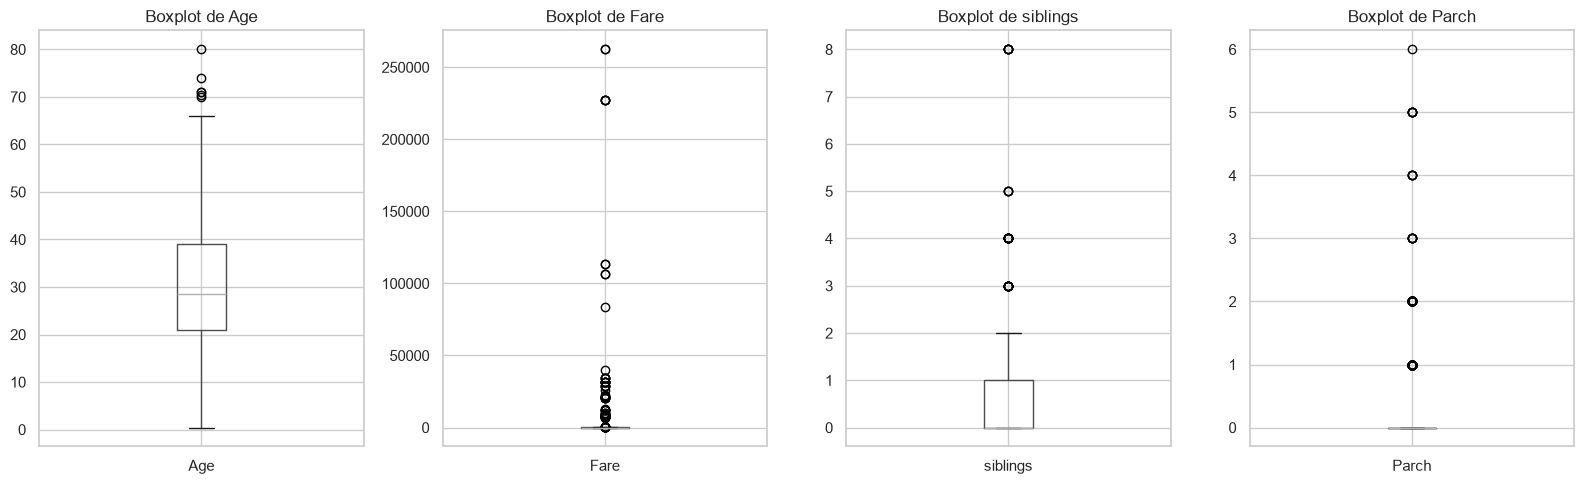

In [90]:
# 1. Selecionamos as variáveis numéricas relevantes para análise de outliers
colunas_numericas = ["Age", "Fare", "siblings", "Parch"]
# 2. Cálculo do IQR e identificação dos outliers
resumo_outliers = []
indices_outliers = {}
for col in colunas_numericas:
    # Remove nulos para o cálculo dos quantis
    dados_validos = df[col].dropna()
    
    q1 = dados_validos.quantile(0.25)
    q3 = dados_validos.quantile(0.75)
    iqr = q3 - q1
    
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    
    # Máscara para identificar os outliers
    mask_outlier = (df[col] < limite_inferior) | (df[col] > limite_superior)
    qtd_outliers = mask_outlier.sum()
    pct_outliers = (qtd_outliers / len(df)) * 100
    
    indices_outliers[col] = df[mask_outlier].index
    
    resumo_outliers.append({
        "Feature": col,
        "Q1 (25%)": round(q1, 2),
        "Mediana (50%)": round(dados_validos.median(), 2),
        "Q3 (75%)": round(q3, 2),
        "IQR": round(iqr, 2),
        "Limite Inferior": round(limite_inferior, 2),
        "Limite Superior": round(limite_superior, 2),
        "Qtd Outliers": qtd_outliers,
        "% Outliers": f"{pct_outliers:.2f}%"
    })
# Exibe tabela com os limites e quantidades
df_resumo_outliers = pd.DataFrame(resumo_outliers)
print("Resumo de Outliers pelo Método IQR:")
display(df_resumo_outliers)
# 3. Visualização Gráfica (Boxplots)
fig, axes = plt.subplots(nrows=1, ncols=len(colunas_numericas), figsize=(16, 5))
for i, col in enumerate(colunas_numericas):
    df.boxplot(column=col, ax=axes[i], grid=True)
    axes[i].set_title(f"Boxplot de {col}")
plt.tight_layout()
plt.show()

- Age: Os outliers são os idosos com mais de 66 anos 
- Fare: Muitos viajavam sozinhos e outros com familia, oque muda bastante o valor 

Primeiras linhas com as novas features:


,Name,siblings,Parch,family_size,is_alone,Fare,fare_per_person,Survived
0,"Braund, Mr. Owen Harris",1,0,2,0,7.2500,3.62500,0
1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,0,2,0,71.2833,35.64165,1
2,"Heikkinen, Miss. Laina",0,0,1,1,7925.0000,7925.00000,1
3,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,0,2,0,53.1000,26.55000,1
4,"Moran, Mr. James",0,0,1,1,8.4583,8.45830,0



Comparativo Estatístico: Fare Total vs Fare por Pessoa:


,Fare,fare_per_person
count,712.00,712.00
mean,4380.21,2551.36
std,24034.87,16685.45
min,0.00,0.00
25%,8.05,7.75
50%,19.38,10.50
75%,56.93,30.99
max,262375.00,227525.00


,Feature,IQR,Limite Superior (Outlier),Qtd Outliers,% Outliers
0,Fare,48.88,130.25,114,16.01%
1,fare_per_person,23.24,65.86,123,17.28%


C:\Users\luanb\AppData\Local\Temp\ipykernel_23348\3189951886.py:69: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_transformed, x="family_size", y="Survived", ax=axes[1, 1], palette="Blues_d", errorbar=None)


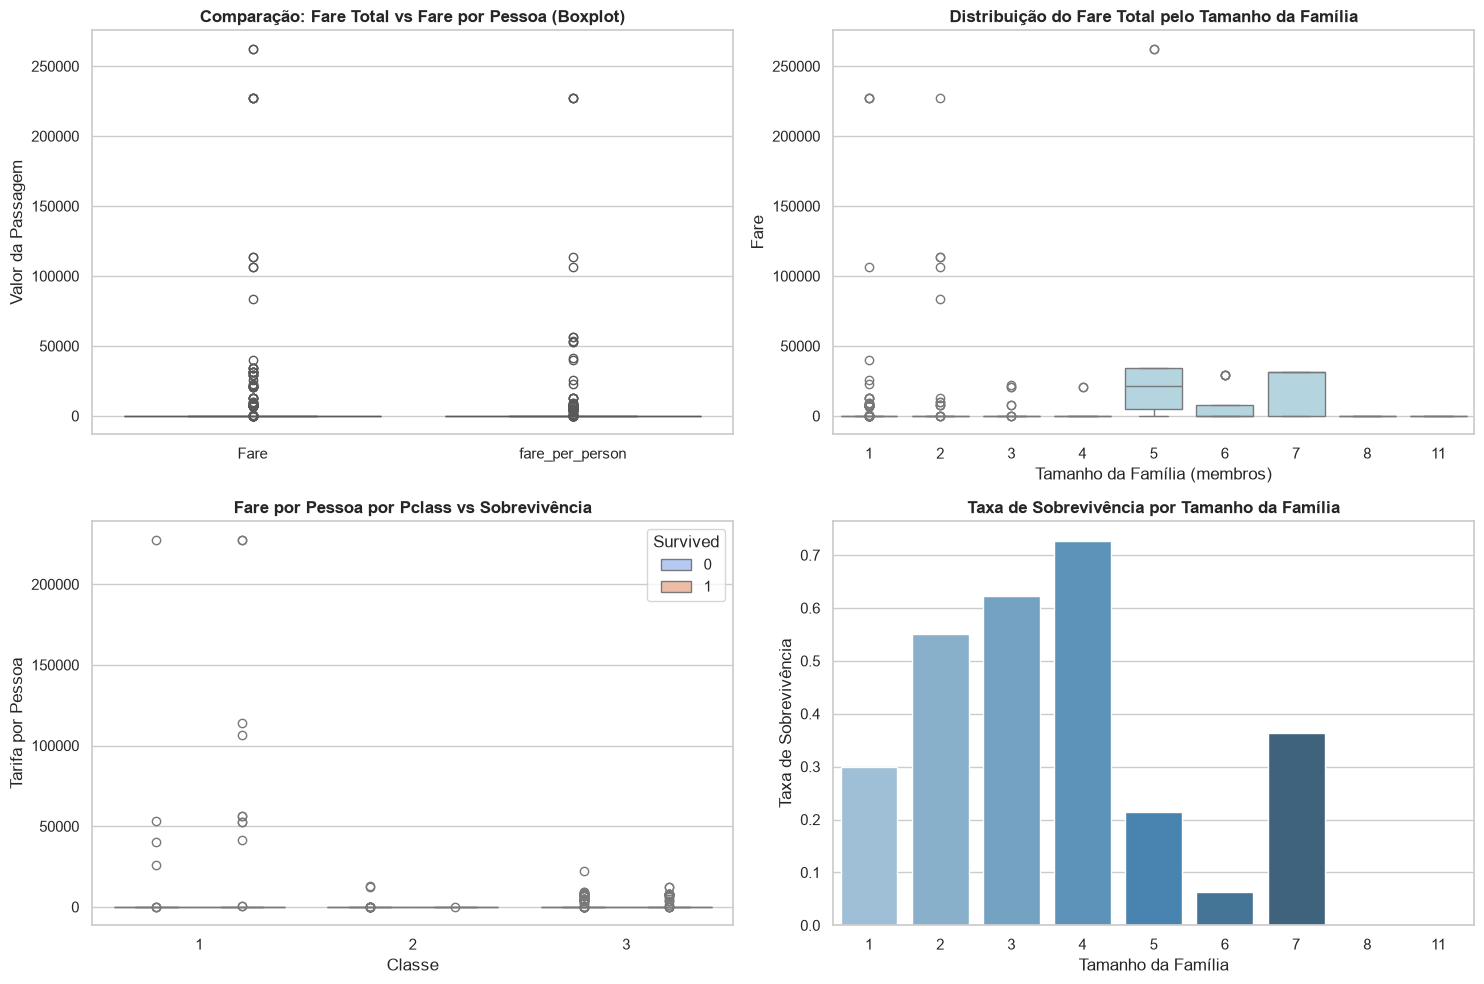


Correlações com Sobrevivência (Survived):


Survived           1.000000
Fare               0.076157
fare_per_person    0.065001
family_size        0.026967
is_alone          -0.215570
Name: Survived, dtype: float64

In [104]:
df_transformed = df.copy()
sns.set_theme(style="whitegrid")

# 1. Criação das features de Família
# family_size: total de membros (irmãos + cônjuges + pais + filhos + o próprio passageiro)
df_transformed["family_size"] = df["siblings"] + df["Parch"] + 1

# Classificação em categorias de tamanho de família
df_transformed["is_alone"] = (df_transformed["family_size"] == 1).astype(int)

# Tarifa individual estimada (evita a distorção do bilhete conjunto)
df_transformed["fare_per_person"] = df_transformed["Fare"] / df_transformed["family_size"]

print("Primeiras linhas com as novas features:")
display(df_transformed[["Name", "siblings", "Parch", "family_size", "is_alone", "Fare", "fare_per_person", "Survived"]].head())

# -------------------------------------------------------------
# 2. Estatísticas Descritivas: Fare Total vs Fare por Pessoa
# -------------------------------------------------------------
print("\nComparativo Estatístico: Fare Total vs Fare por Pessoa:")
display(df_transformed[["Fare", "fare_per_person"]].describe().round(2))

# -------------------------------------------------------------
# 3. Análise de Outliers: Fare Total vs Fare por Pessoa (IQR)
# -------------------------------------------------------------
resumo_fare_outliers = []
for col in ["Fare", "fare_per_person"]:
    dados = df_transformed[col].dropna()
    valor_iqr = iqr(dados)
    q1 = dados.quantile(0.25)
    q3 = dados.quantile(0.75)
    sup = q3 + 1.5 * valor_iqr
    
    qtd_outliers = (dados > sup).sum()
    pct_outliers = (qtd_outliers / len(dados)) * 100
    
    resumo_fare_outliers.append({
        "Feature": col,
        "IQR": round(valor_iqr, 2),
        "Limite Superior (Outlier)": round(sup, 2),
        "Qtd Outliers": qtd_outliers,
        "% Outliers": f"{pct_outliers:.2f}%"
    })

display(pd.DataFrame(resumo_fare_outliers))

# -------------------------------------------------------------
# 4. Visualizações Gráficas
# -------------------------------------------------------------
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(15, 10))

# Gráfico 1: Comparação de Outliers (Boxplot) Fare vs Fare por Pessoa
sns.boxplot(data=df_transformed[["Fare", "fare_per_person"]], ax=axes[0, 0], palette="Set2")
axes[0, 0].set_title("Comparação: Fare Total vs Fare por Pessoa (Boxplot)", fontweight="bold")
axes[0, 0].set_ylabel("Valor da Passagem")

# Gráfico 2: Fare por Tamanho de Família (Mostra como famílias maiores pagavam mais no total)
sns.boxplot(data=df_transformed, x="family_size", y="Fare", ax=axes[0, 1], color="lightblue")
axes[0, 1].set_title("Distribuição do Fare Total pelo Tamanho da Família", fontweight="bold")
axes[0, 1].set_xlabel("Tamanho da Família (membros)")

# Gráfico 3: Fare por Pessoa por Classe (Pclass) e Sobrevivência
sns.boxplot(data=df_transformed, x="Pclass", y="fare_per_person", hue="Survived", ax=axes[1, 0], palette="coolwarm")
axes[1, 0].set_title("Fare por Pessoa por Pclass vs Sobrevivência", fontweight="bold")
axes[1, 0].set_xlabel("Classe")
axes[1, 0].set_ylabel("Tarifa por Pessoa")

# Gráfico 4: Taxa de Sobrevivência por Tamanho da Família
sns.barplot(data=df_transformed, x="family_size", y="Survived", ax=axes[1, 1], palette="Blues_d", errorbar=None)
axes[1, 1].set_title("Taxa de Sobrevivência por Tamanho da Família", fontweight="bold")
axes[1, 1].set_xlabel("Tamanho da Família")
axes[1, 1].set_ylabel("Taxa de Sobrevivência")

plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# 5. Correlação com Sobrevivência
# -------------------------------------------------------------
print("\nCorrelações com Sobrevivência (Survived):")
display(df[["Fare", "fare_per_person", "family_size", "is_alone", "Survived"]].corr()["Survived"].sort_values(ascending=False))

## Analisando a Distribuição dos dados

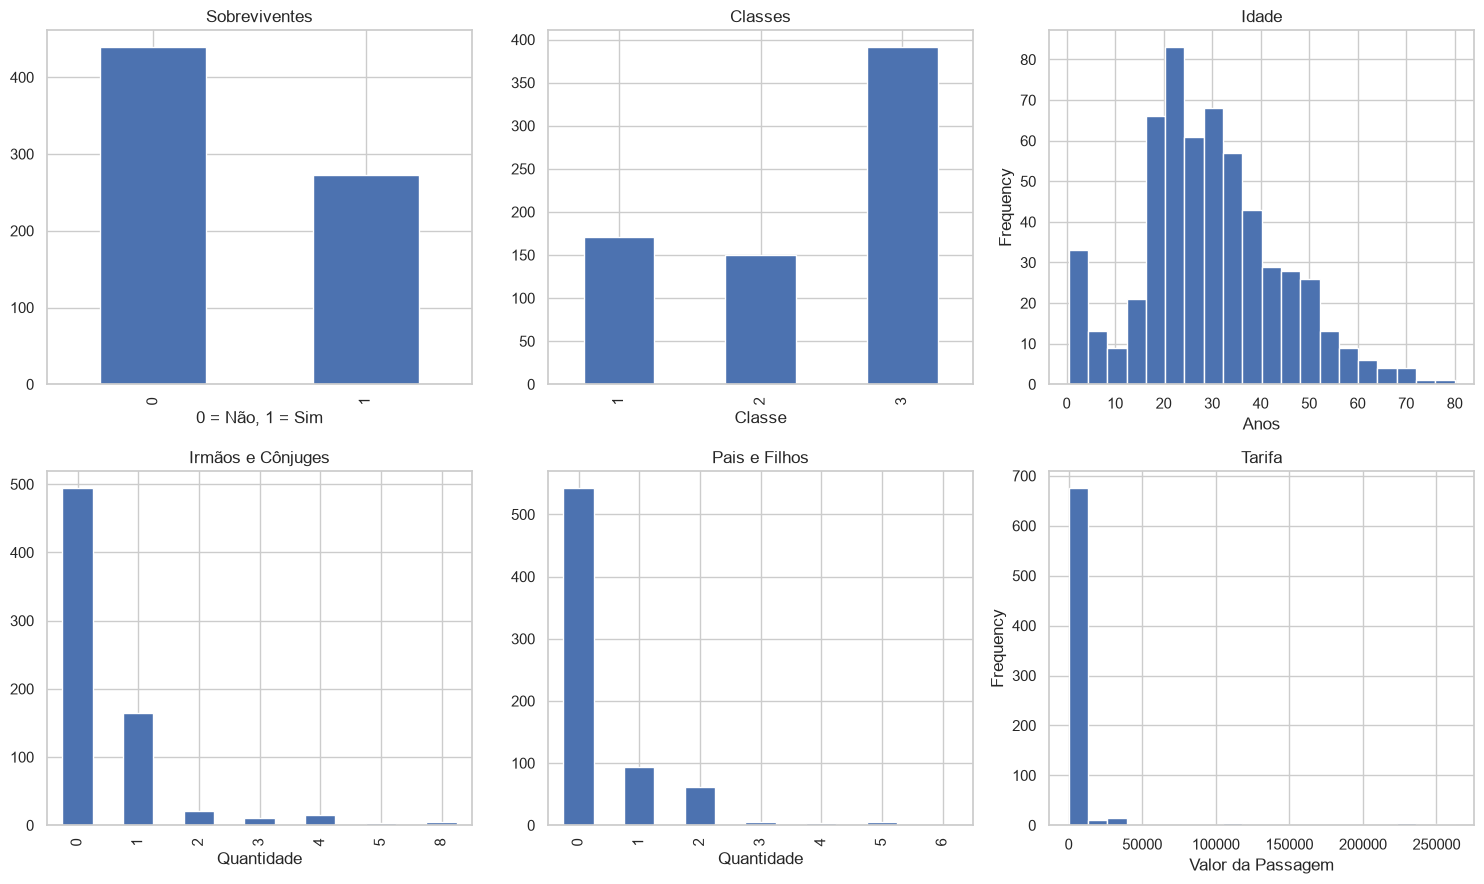

In [44]:
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(15, 9))
# 1. Sobreviventes
df["Survived"].value_counts().plot(kind="bar", ax=axes[0, 0], title="Sobreviventes")
axes[0, 0].set_xlabel("0 = Não, 1 = Sim")
# 2. Classes
df["Pclass"].value_counts().sort_index().plot(kind="bar", ax=axes[0, 1], title="Classes")
axes[0, 1].set_xlabel("Classe")
# 3. Idade
df["Age"].plot(kind="hist", bins=20, ax=axes[0, 2], title="Idade")
axes[0, 2].set_xlabel("Anos")
# 4. Irmãos / Cônjuges (siblings em minúsculo)
df["siblings"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 0], title="Irmãos e Cônjuges")
axes[1, 0].set_xlabel("Quantidade")
# 5. Pais / Filhos
df["Parch"].value_counts().sort_index().plot(kind="bar", ax=axes[1, 1], title="Pais e Filhos")
axes[1, 1].set_xlabel("Quantidade")
# 6. Tarifa
df["Fare"].plot(kind="hist", bins=20, ax=axes[1, 2], title="Tarifa")
axes[1, 2].set_xlabel("Valor da Passagem")
plt.tight_layout()
plt.show()

## investigação das relações entre as características dos passageiros e a sobrevivência.

Estatistica Descritiva de cada feature


,Survived,Pclass,Age,siblings,Parch,Fare
count,712.000000,712.000000,575.000000,712.000000,712.000000,712.000000
mean,0.383427,2.308989,29.807687,0.492978,0.390449,4380.205852
std,0.486563,0.833563,14.485211,1.060720,0.838134,24034.866901
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,21.000000,0.000000,0.000000,8.050000
50%,0.000000,3.000000,28.500000,0.000000,0.000000,19.379150
75%,1.000000,3.000000,39.000000,1.000000,0.000000,56.929200
max,1.000000,3.000000,80.000000,8.000000,6.000000,262375.000000


Correlação entre as features
Features mais relevantes para a Sobrevivência:


Survived      1.000000
Sex           0.549171
Embarked_C    0.180029
Embarked_S   -0.186567
Pclass       -0.348007
Name: Survived, dtype: float64

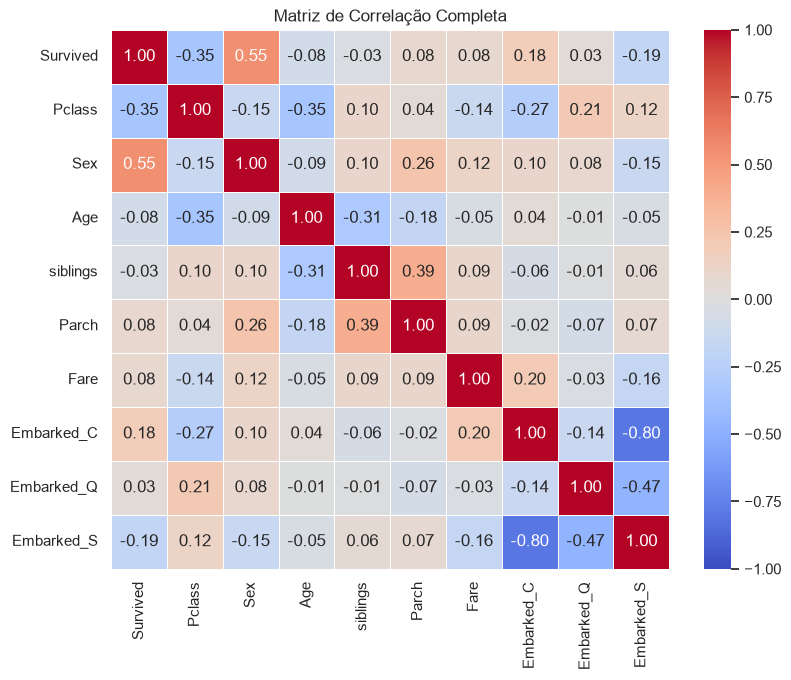

In [ ]:
print("Estatistica Descritiva de cada feature")
display(df.describe())

print("Correlação entre as features")
map_sex = {
    "male": 0,
    "female": 1
}

# Tratamento de dados str para int64, permitindo que correlacionemos com Survived
df_transformed["Sex"] = df["Sex"].map(map_sex)

# One-Hot Encoding para Embarked (gera colunas: Embarked_C, Embarked_Q, Embarked_S com 0 ou 1)
df_transformed = pd.get_dummies(df_transformed, columns=["Embarked"], dtype=int)

# Calculando a matriz de correlação
matriz_correlacao = df_transformed.select_dtypes(include=["float64", "int64"]).corr()

corr_alvo = matriz_correlacao["Survived"].sort_values(ascending=False)
# Mostra apenas variáveis com correlação relevante (ex: maior que 0.1 ou menor que -0.1)
relevantes = corr_alvo[abs(corr_alvo) > 0.1]
print("Features mais relevantes para a Sobrevivência:")
display(relevantes)

plt.figure(figsize=(9, 7))
# Plot do mapa de calor com valores em cada célula
sns.heatmap(
    matriz_correlacao,
    annot=True,          # Mostra os valores numéricos
    fmt=".2f",           # 2 casas decimais
    cmap="coolwarm",     # Azul (negativo) -> Vermelho (positivo)
    vmin=-1, vmax=1,     # Escala de -1 a 1
    linewidths=0.5
)
plt.title("Matriz de Correlação Completa")
plt.show()

*Interpretaçao da Correlaçao de Pearson*

- 0.00 a 0.19: Correlação bem fraca ou irrelevante.
- 0.20 a 0.39: Correlação fraca/moderada.
- 0.40 a 0.69: Correlação moderada/forte (aqui o sinal de alerta acende).
- 0.70 a 1.00: Correlação muito forte (indica forte dependência linear).


Deck_D          0.169875
Deck_B          0.162058
Deck_E          0.159005
Deck_C          0.152263
Deck_F          0.088586
Deck_G          0.018021
Deck_A          0.013149
Deck_T         -0.029574
Deck_Unknown   -0.350535
Name: Survived, dtype: float64

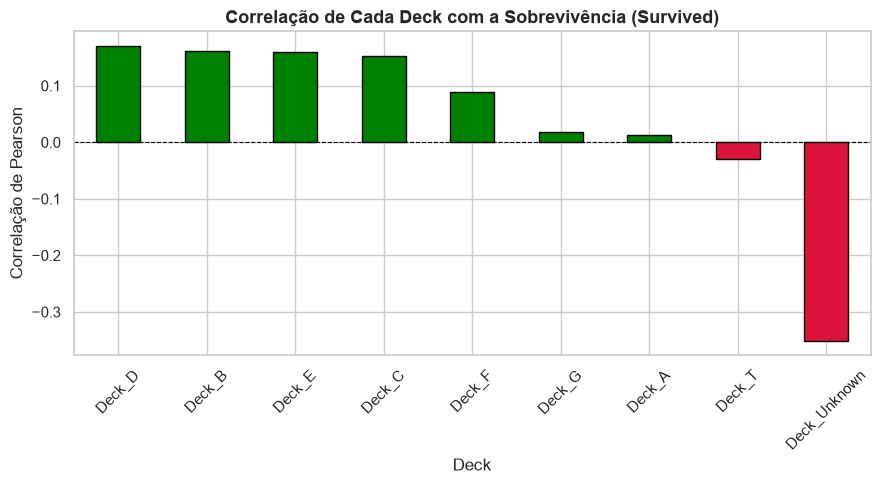

In [99]:
# 1. Extrai a primeira letra da cabine (se for nula, preenche com 'Unknown')
df_transformed["Deck"] = df["Cabin"].str[0].fillna("Unknown")
# 2. Transforma em colunas 0 e 1 (One-Hot Encoding) garantindo tipo numérico
df_transformed = pd.get_dummies(df_transformed, columns=["Deck"], dtype=int)
# 3. Calcula a correlação de todos os Decks com a sobrevivência
corr_decks = df_transformed.select_dtypes(include=["number"]).corr()["Survived"]
decks_corr = corr_decks.filter(like="Deck_").sort_values(ascending=False)
# Exibe os valores em texto/tabela
display(decks_corr)
# 4. Gera o Gráfico de Barras da Correlação com Seaborn / Matplotlib
plt.figure(figsize=(9, 5))
cores = ["green" if valor > 0 else "crimson" for valor in decks_corr.values]
decks_corr.plot(kind="bar", color=cores, edgecolor="black")
plt.title("Correlação de Cada Deck com a Sobrevivência (Survived)", fontsize=13, fontweight="bold")
plt.xlabel("Deck")
plt.ylabel("Correlação de Pearson")
plt.axhline(0, color="black", linestyle="--", linewidth=0.8) # Linha zero de referência
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()